<a href="https://colab.research.google.com/github/nvhlovewho-bit/ThucHanh_HocMay_HUIT/blob/main/TH_HocMay_Buoi_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### PHẦN 1: TUẦN 1 — HỒI QUY (REGRESSION)

Nội dung trọng tâm:
1. **Hồi quy tuyến tính (Linear Regression):** Dự đoán một giá trị số liên tục (ví dụ: giá nhà, nhiệt độ). Đo lường hiệu quả bằng sai số bình phương trung bình (**MSE** - càng nhỏ càng tốt) và hệ số xác định (**$R^2$ score** - càng gần 1 càng tốt).
2. **Hồi quy Logistic (Logistic Regression):** Phân loại dữ liệu vào các nhóm riêng biệt (như Có/Không, 0/1) bằng cách chuyển đổi đầu ra thành xác suất từ 0 đến 1 qua hàm Sigmoid. Đánh giá bằng độ chính xác (**Accuracy**), ma trận nhầm lẫn (**Confusion Matrix**) và các chỉ số chuyên sâu (**Precision, Recall, F1-score**).

## 1.1. Thực hành: Hồi quy tuyến tính đơn biến (1 biến đầu vào)

**Điểm cốt lõi:**
- **Dữ liệu giả lập:** Tạo ra 100 điểm dữ liệu xoay quanh đường thẳng $y = 4 + 3x$ kết hợp thêm một chút sai số ngẫu nhiên (nhiễu) để mô phỏng thực tế.
- **Chia tập dữ liệu:** Tách 80% dữ liệu để máy học mẫu (tập Train) và giữ lại 20% độc lập để kiểm tra năng lực dự đoán (tập Test).
- **Đọc kết quả:** Hệ số chặn (`intercept_`) ước lượng điểm xuất phát của đường thẳng ($	heta_0 \approx 4$), hệ số góc (`coef_`) ước lượng độ dốc ($	heta_1 \approx 3$).

Hệ số chặn (Intercept): 4.2063
Hệ số góc (Slope): 2.9903
Mean Squared Error (MSE): 0.9178
R^2 score: 0.6521


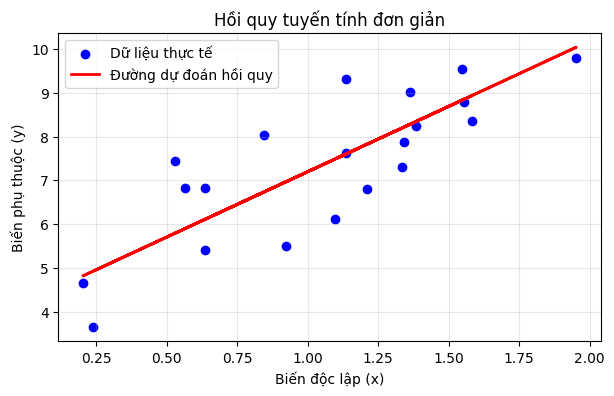

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tạo dữ liệu ngẫu nhiên
np.random.seed(0)
x = 2 * np.random.rand(100, 1)               # Biến đầu vào x trong [0, 2)
y = 4 + 3 * x + np.random.randn(100, 1)      # Biến đầu ra y = 4 + 3x + nhiễu Gaussian

# 2. Chia dữ liệu thành tập huấn luyện (80%) và tập kiểm tra (20%)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# 3. Khởi tạo và huấn luyện mô hình hồi quy tuyến tính
model = LinearRegression()
model.fit(x_train, y_train)

# 4. Dự đoán trên tập kiểm tra
y_pred = model.predict(x_test)

# 5. Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Hệ số chặn (Intercept): {model.intercept_[0]:.4f}")
print(f"Hệ số góc (Slope): {model.coef_[0][0]:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 score: {r2:.4f}")

# 6. Vẽ biểu đồ trực quan
plt.figure(figsize=(7, 4))
plt.scatter(x_test, y_test, color="blue", label="Dữ liệu thực tế")
plt.plot(x_test, y_pred, color="red", linewidth=2, label="Đường dự đoán hồi quy")
plt.title("Hồi quy tuyến tính đơn giản")
plt.xlabel("Biến độc lập (x)")
plt.ylabel("Biến phụ thuộc (y)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 1.2. Thực hành: Hồi quy tuyến tính đa biến (nhiều biến đầu vào)

**Điểm cốt lõi:**
- Trong thực tế, một kết quả thường bị ảnh hưởng bởi nhiều yếu tố cùng lúc. Ở đây, mô hình sẽ học cách dự đoán từ 3 biến độc lập $x_1, x_2, x_3$.
- Công thức gốc tạo dữ liệu: $y = 4 + 3x_1 + 2x_2 + 5x_3 + \text{nhiễu}$.
- Sau khi huấn luyện, mô hình sẽ tìm ra 3 hệ số hồi quy tương ứng cho từng biến để phản ánh mức độ ảnh hưởng của từng yếu tố lên kết quả cuối cùng.

In [18]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tạo dữ liệu giả lập với 3 biến đầu vào
np.random.seed(0)
X = 2 * np.random.rand(100, 3)
y = 4 + 3 * X[:, 0] + 2 * X[:, 1] + 5 * X[:, 2] + np.random.randn(100)

# 2. Chia dữ liệu train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Huấn luyện mô hình
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Dự đoán và đánh giá
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Hệ số chặn (Intercept): {model.intercept_:.4f}")
print(f"Hệ số hồi quy (Coefficients): {np.round(model.coef_, 4)}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 score: {r2:.4f}")

Hệ số chặn (Intercept): 4.0163
Hệ số hồi quy (Coefficients): [2.9344 1.88   5.0436]
Mean Squared Error (MSE): 1.0965
R^2 score: 0.9187


## 1.3. Thực hành: Hồi quy Logistic (Phân loại nhị phân trên tập hoa Iris)

**Điểm cốt lõi:**
- **Lọc dữ liệu:** Tập dữ liệu gốc có 3 nhóm hoa khác nhau, nhưng để làm bài toán phân loại nhị phân đơn giản (đúng/sai), code chỉ giữ lại 2 nhóm là Setosa (nhãn 0) và Versicolor (nhãn 1).
- **Cách hoạt động:** Thay vì vẽ đường thẳng đi lên vô hạn, mô hình bẻ cong kết quả dự đoán về dạng chữ S (hàm Sigmoid) để trả về một mức xác suất. Nếu xác suất lớn hơn hoặc bằng 0.5, mẫu dữ liệu được phân vào nhóm 1, ngược lại là nhóm 0.
- **Đánh giá:** Ma trận nhầm lẫn sẽ thống kê chi tiết có bao nhiêu mẫu dự đoán đúng và bao nhiêu mẫu bị đoán lệch nhóm.

In [19]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tải dữ liệu hoa Iris và lọc lấy 2 lớp (0 và 1) cho phân loại nhị phân
iris = load_iris()
X = iris['data']
y = iris['target']

X = X[y != 2]
y = y[y != 2]

# 2. Chia dữ liệu 80% huấn luyện, 20% kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Tạo và huấn luyện mô hình Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# 5. Đánh giá mô hình
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=iris.target_names[:2])

print(f"Độ chính xác (Accuracy): {accuracy:.4f}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("\nBáo cáo phân loại (Classification Report):")
print(class_report)

Độ chính xác (Accuracy): 1.0000
Ma trận nhầm lẫn (Confusion Matrix):
[[12  0]
 [ 0  8]]

Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



## 1.4. Bài tập tại lớp 1: Dự đoán giá nhà theo diện tích và các yếu tố đi kèm

**Mục tiêu huấn luyện:**
- **Ý 1:** Thực hành xây dựng mô hình hồi quy tuyến tính đơn giản nhất chỉ dựa vào diện tích với giả định dữ liệu ít biến động.
- **Ý 2:** Thử thách mô hình bằng cách tăng lượng dữ liệu và đẩy mạnh độ nhiễu (biến động giá cực lớn) để quan sát sự sụt giảm của chỉ số $R^2$.
- **Ý 3:** Mở rộng mô hình lên đa biến bằng cách nạp thêm thông tin về số phòng ngủ và khoảng cách tới trung tâm để tối ưu hóa khả năng định giá.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

# --- YÊU CẦU 1: Hồi quy tuyến tính đơn giản (50 mẫu, nhiễu nhỏ) ---
dien_tich = np.random.uniform(30, 150, (50, 1))
gia_ban = 500 + 35 * dien_tich + np.random.normal(0, 150, (50, 1))

X_tr1, X_te1, y_tr1, y_te1 = train_test_split(dien_tich, gia_ban, test_size=0.2, random_state=42)
m1 = LinearRegression().fit(X_tr1, y_tr1)
pred1 = m1.predict(X_te1)
print(f"[Ý 1 - Đơn biến, ít nhiễu] MSE = {mean_squared_error(y_te1, pred1):.2f} | R^2 = {r2_score(y_te1, pred1):.4f}")

# --- YÊU CẦU 2: Tăng số lượng dữ liệu (500 mẫu) và tăng độ nhiễu ---
dien_tich_2 = np.random.uniform(30, 150, (500, 1))
gia_ban_2 = 500 + 35 * dien_tich_2 + np.random.normal(0, 800, (500, 1))  # Tăng std nhiễu lên 800

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(dien_tich_2, gia_ban_2, test_size=0.2, random_state=42)
m2 = LinearRegression().fit(X_tr2, y_tr2)
pred2 = m2.predict(X_te2)
print(f"[Ý 2 - Tăng mẫu & nhiễu lớn] MSE = {mean_squared_error(y_te2, pred2):.2f} | R^2 = {r2_score(y_te2, pred2):.4f}")

# --- YÊU CẦU 3: Thêm biến đầu vào (Diện tích, Số phòng ngủ, Khoảng cách tới trung tâm) ---
n = 200
s = np.random.uniform(30, 150, (n, 1))         # Diện tích (m2)
phong = np.random.randint(1, 5, (n, 1))        # Số phòng ngủ (1 - 4)
xa_tt = np.random.uniform(1, 20, (n, 1))       # Khoảng cách trung tâm (km)

X_multi = np.hstack([s, phong, xa_tt])
y_multi = 500 + 35 * s + 120 * phong - 40 * xa_tt + np.random.normal(0, 150, (n, 1))

X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)
m3 = LinearRegression().fit(X_tr3, y_tr3)
pred3 = m3.predict(X_te3)
print(f"[Ý 3 - Đa biến] Hệ số: {np.round(m3.coef_[0], 2)} | MSE = {mean_squared_error(y_te3, pred3):.2f} | R^2 = {r2_score(y_te3, pred3):.4f}")

[Ý 1 - Đơn biến, ít nhiễu] MSE = 17916.85 | R^2 = 0.9798
[Ý 2 - Tăng mẫu & nhiễu lớn] MSE = 640477.94 | R^2 = 0.7437
[Ý 3 - Đa biến] Hệ số: [ 35.18 119.72 -35.83] | MSE = 23709.67 | R^2 = 0.9816


## 1.5. Bài tập tại lớp 2: Dự đoán nguy cơ mắc bệnh dựa trên chỉ số thể trọng BMI

**Điểm cốt lõi:**
- **Logic dữ liệu:** Giả lập thực tế khi chỉ số thể trọng BMI tăng cao vượt ngưỡng an toàn (mốc 26), nguy cơ mắc bệnh sẽ tăng lên rõ rệt.
- **Đường cong xác suất:** Biểu đồ trực quan hóa đường cong Sigmoid màu đỏ thể hiện trực quan xu hướng: BMI càng lớn thì khả năng bị gắn nhãn 1 (mắc bệnh) càng tiệm cận mức 100%.

5 xác suất mắc bệnh đầu tiên trên tập test: [0.807 0.012 0.973 0.032 0.   ]
5 nhãn dự đoán tương ứng: [1 0 1 0 0]

Độ chính xác (Accuracy): 0.8500
Ma trận nhầm lẫn (Confusion Matrix):
[[15  3]
 [ 3 19]]


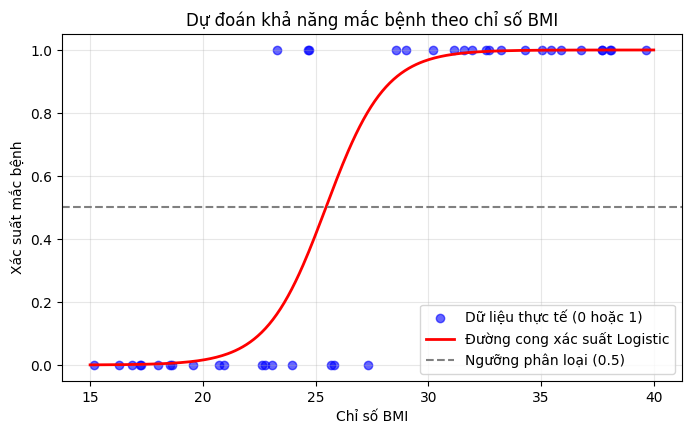

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)

# 1. Tạo dữ liệu mẫu giả lập hợp logic
BMI = np.random.uniform(15, 40, (200, 1))
mac_benh = ((BMI + np.random.normal(0, 2.5, (200, 1))) > 26).astype(int).ravel()

# Chia train/test
X_train, X_test, y_train, y_test = train_test_split(BMI, mac_benh, test_size=0.2, random_state=42)

# 2 & 3. Xây dựng và huấn luyện mô hình Logistic Regression
model_bmi = LogisticRegression()
model_bmi.fit(X_train, y_train)

# 4. Dự đoán xác suất và nhãn mắc bệnh
y_prob = model_bmi.predict_proba(X_test)[:, 1]
y_pred = model_bmi.predict(X_test)

print("5 xác suất mắc bệnh đầu tiên trên tập test:", np.round(y_prob[:5], 3))
print("5 nhãn dự đoán tương ứng:", y_pred[:5])

# 5. Đánh giá mô hình
print(f"\nĐộ chính xác (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))

# 6. Trực quan hóa dữ liệu và đường hồi quy logistic
bmi_range = np.linspace(15, 40, 300).reshape(-1, 1)
prob_curve = model_bmi.predict_proba(bmi_range)[:, 1]

plt.figure(figsize=(8, 4.5))
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Dữ liệu thực tế (0 hoặc 1)')
plt.plot(bmi_range, prob_curve, color='red', linewidth=2, label='Đường cong xác suất Logistic')
plt.axhline(0.5, color='gray', linestyle='--', label='Ngưỡng phân loại (0.5)')
plt.title("Dự đoán khả năng mắc bệnh theo chỉ số BMI")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 1.6. Bài tập tại lớp 3: Huấn luyện trên dữ liệu thực tế California Housing

**Điểm cốt lõi:**
- Áp dụng toàn bộ quy trình xử lý dữ liệu chuẩn hóa vào bài toán thực tế sử dụng bộ dữ liệu nhà ở California từ thư viện `scikit-learn`.
- Quy trình triển khai bao gồm: Nạp dữ liệu -> Kiểm tra dọn dẹp các ô trống bị thiếu -> Phân tách biến đầu vào và biến mục tiêu -> Huấn luyện mô hình -> Đánh giá sai số thực tế trên tập Test độc lập.

In [22]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải và khám phá dữ liệu
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['Target_Price'] = housing.target

print("Kích thước bộ dữ liệu:", df.shape)
print("Tổng số giá trị thiếu:", df.isnull().sum().sum())
print(df.head(3))

# 2. Tách biến độc lập X và biến mục tiêu y
X = df.drop('Target_Price', axis=1)
y = df['Target_Price']

# 3. Chia train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Huấn luyện mô hình Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Dự đoán và đánh giá
y_pred = model.predict(X_test)
print(f"\nMSE trên tập test: {mean_squared_error(y_test, y_pred):.4f}")
print(f"R^2 score trên tập test: {r2_score(y_test, y_pred):.4f}")

Kích thước bộ dữ liệu: (20640, 9)
Tổng số giá trị thiếu: 0
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   

   Longitude  Target_Price  
0    -122.23         4.526  
1    -122.22         3.585  
2    -122.24         3.521  

MSE trên tập test: 0.5559
R^2 score trên tập test: 0.5758


## 1.7. Bài tập về nhà 1: Tác động của nhiễu dữ liệu lên mô hình hồi quy

**Điểm cốt lõi:**
- Tiến hành thử nghiệm chạy mô hình qua 4 mức độ nhiễu khác nhau (từ rất ổn định 0.5 đến cực kỳ biến động 5.0).
- Biểu đồ so sánh trực quan cho thấy: Khi dữ liệu thực tế bị phân tán quá xa khỏi quy luật chung, sai số MSE sẽ tăng vọt và độ tin cậy $R^2$ sẽ giảm sút nghiêm trọng, chứng minh tầm quan trọng của việc làm sạch dữ liệu trước khi huấn luyện.

Nhiễu std =  0.5 | Intercept = 4.01 | Slope = 3.03 | MSE =  0.2712 | R^2 =  0.9087
Nhiễu std =  1.5 | Intercept = 3.89 | Slope = 3.07 | MSE =  2.4454 | R^2 =  0.5754
Nhiễu std =  3.0 | Intercept = 5.21 | Slope = 2.42 | MSE =  9.4166 | R^2 =  0.1532
Nhiễu std =  5.0 | Intercept = 4.78 | Slope = 2.46 | MSE = 24.6418 | R^2 =  0.0807


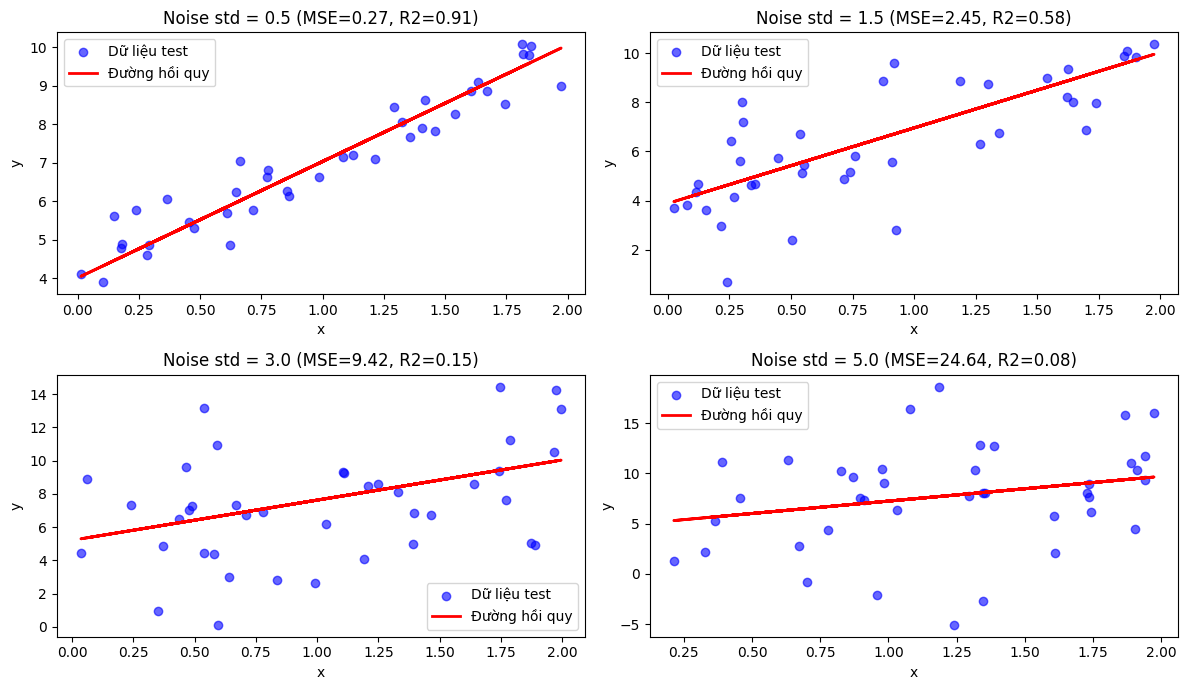

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
noise_levels = [0.5, 1.5, 3.0, 5.0]

plt.figure(figsize=(12, 7))

for idx, noise_std in enumerate(noise_levels, start=1):
    X = 2 * np.random.rand(200, 1)
    y = 4 + 3 * X + np.random.normal(0, noise_std, (200, 1))

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"Nhiễu std = {noise_std:4.1f} | Intercept = {model.intercept_[0]:.2f} | Slope = {model.coef_[0][0]:.2f} | MSE = {mse:7.4f} | R^2 = {r2:7.4f}")

    plt.subplot(2, 2, idx)
    plt.scatter(X_test, y_test, color="blue", alpha=0.6, label="Dữ liệu test")
    plt.plot(X_test, y_pred, color="red", linewidth=2, label="Đường hồi quy")
    plt.title(f"Noise std = {noise_std} (MSE={mse:.2f}, R2={r2:.2f})")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()

plt.tight_layout()
plt.show()

## 1.8. Bài tập về nhà 2: Tùy chỉnh ngưỡng quyết định (Threshold) trong phân loại

**Điểm cốt lõi:**
- Mặc định, các mô hình phân loại sẽ chọn mốc xác suất 50% (0.5) làm ranh giới phân tách nhóm.
- Việc chủ động thay đổi ngưỡng này (lên 0.6, 0.7, hoặc 0.8) giúp kiểm soát mức độ khắt khe khi đưa ra quyết định dự đoán. Ngưỡng càng cao, mô hình càng thận trọng khi gắn nhãn nhóm 1, giúp giảm thiểu sai sót báo động giả nhưng đồng thời có khả năng bỏ sót nhiều trường hợp thực tế.

In [24]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)

# Tạo dữ liệu phân loại nhị phân
X = np.random.uniform(15, 40, (250, 1))
logits = -6.5 + 0.25 * X.ravel() + np.random.normal(0, 0.6, 250)
y = ((1 / (1 + np.exp(-logits))) >= 0.5).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression().fit(X_train, y_train)
y_prob = model.predict_proba(X_test)[:, 1]

for th in [0.5, 0.6, 0.7, 0.8]:
    y_pred_th = (y_prob >= th).astype(int)
    print("=" * 50)
    print(f"Ngưỡng xác suất (threshold) = {th} | Số mẫu dự đoán lớp 1: {y_pred_th.sum()}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred_th):.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_th))

Ngưỡng xác suất (threshold) = 0.5 | Số mẫu dự đoán lớp 1: 29
Accuracy: 0.9600
Confusion Matrix:
 [[20  1]
 [ 1 28]]
Ngưỡng xác suất (threshold) = 0.6 | Số mẫu dự đoán lớp 1: 27
Accuracy: 0.9600
Confusion Matrix:
 [[21  0]
 [ 2 27]]
Ngưỡng xác suất (threshold) = 0.7 | Số mẫu dự đoán lớp 1: 26
Accuracy: 0.9400
Confusion Matrix:
 [[21  0]
 [ 3 26]]
Ngưỡng xác suất (threshold) = 0.8 | Số mẫu dự đoán lớp 1: 25
Accuracy: 0.9200
Confusion Matrix:
 [[21  0]
 [ 4 25]]


## 1.9. Bài tập về nhà 3: Dự báo giá nhà với tập dữ liệu kinh điển Boston Housing

**Điểm cốt lõi:**
- Triển khai bài toán hồi quy tuyến tính đa biến trên tập dữ liệu nhà ở Boston thông qua cơ chế tự động tải dữ liệu trực tuyến nếu không tìm thấy file cục bộ.
- Đánh giá khả năng suy diễn của mô hình trên dữ liệu mới bằng các chỉ số kiểm định chuẩn hóa.

In [25]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải dữ liệu Boston Housing
possible_files = ["BostonHousing.csv", "boston_housing.csv", "housing.csv", "HousingData.csv"]
found_file = next((f for f in possible_files if os.path.exists(f)), None)

if found_file:
    df = pd.read_csv(found_file)
else:
    url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
    df = pd.read_csv(url)

df_clean = df.dropna().select_dtypes(include=[np.number])
target_col = "medv" if "medv" in df_clean.columns else df_clean.columns[-1]

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

# 2. Chia train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Huấn luyện mô hình Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Dự đoán và đánh giá
y_pred = model.predict(X_test)
print(f"Kích thước dữ liệu: {df_clean.shape} | Biến mục tiêu: '{target_col}'")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"R^2 score: {r2_score(y_test, y_pred):.4f}")

Kích thước dữ liệu: (506, 14) | Biến mục tiêu: 'medv'
Mean Squared Error (MSE): 24.2911
R^2 score: 0.6688


### PHẦN 2: TUẦN 2 — PHÂN LỚP & HỒI QUY VỚI KNN VÀ SVM

Nội dung trọng tâm:
1. **Thuật toán láng giềng gần nhất (KNN):** Quyết định kết quả dựa trên thông tin của các điểm dữ liệu lân cận gần nó nhất. Thuật toán này cực kỳ nhạy cảm với thang đo của dữ liệu, vì vậy việc đưa các biến về cùng một chuẩn (chuẩn hóa dữ liệu bằng `StandardScaler`) là bước chuẩn bị bắt buộc.
2. **Thuật toán máy vectơ hỗ trợ (SVM):** Tìm kiếm một ranh giới tối ưu để phân tách các nhóm dữ liệu một cách rõ ràng nhất. SVM hỗ trợ nhiều dạng chuyển đổi không gian khác nhau (hàm nhân - Kernel) như tuyến tính (`linear`), phi tuyến (`rbf`, `poly`) để giải quyết các cấu trúc dữ liệu phức tạp.

## 2.1. Thực hành: Phân loại hoa bằng thuật toán KNN

**Điểm cốt lõi:**
- Áp dụng thuật toán KNN với tham số $K=3$ (quyết định nhãn dựa trên ý kiến của 3 láng giềng gần nhất).
- Ma trận nhiệt (Heatmap) trực quan hóa kết quả đối chiếu giữa nhãn dự đoán của mô hình và nhãn thực tế của loài hoa để phát hiện ngay các mẫu bị phân loại nhầm.

Độ chính xác của mô hình KNN với K=3: 1.0000
Ma trận nhầm lẫn:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Báo cáo phân loại:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



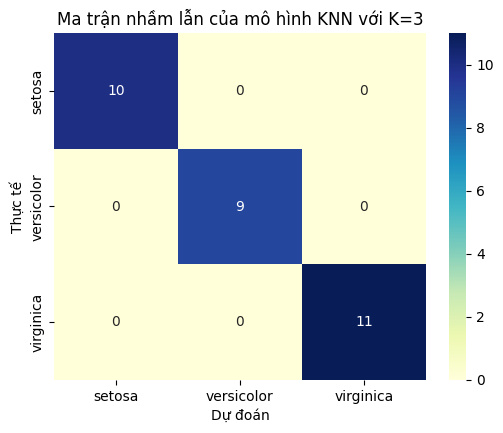

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tải dữ liệu Iris
iris = load_iris()
X = iris.data
y = iris.target

# 2. Chia tập train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Xây dựng và huấn luyện mô hình KNN với K=3
k = 3
knn_model = KNeighborsClassifier(n_neighbors=k)
knn_model.fit(X_train, y_train)

# 4. Dự đoán và đánh giá
y_pred = knn_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Độ chính xác của mô hình KNN với K={k}: {accuracy:.4f}")
print("Ma trận nhầm lẫn:\n", conf_matrix)
print("\nBáo cáo phân loại:\n", classification_report(y_test, y_pred, target_names=iris.target_names))

# 5. Vẽ biểu đồ ma trận nhầm lẫn
plt.figure(figsize=(6, 4.5))
sns.heatmap(conf_matrix, annot=True, cmap="YlGnBu", fmt="d",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.title(f"Ma trận nhầm lẫn của mô hình KNN với K={k}")
plt.show()

## 2.2. Thực hành: Chẩn đoán y khoa bằng thuật toán SVM

**Điểm cốt lõi:**
- Sử dụng thuật toán SVM để giải quyết bài toán phân loại ung thư vú dựa trên các chỉ số đo lường tế bào.
- **Quy tắc vàng về xử lý dữ liệu:** Chỉ học thang đo (gọi hàm `fit_transform`) trên tập huấn luyện, sau đó áp dụng chính xác thang đo đó (chỉ gọi hàm `transform`) lên tập kiểm tra để đảm bảo tính khách quan hoàn hảo cho mô hình.

Độ chính xác của mô hình SVM: 0.9825
Ma trận nhầm lẫn:
 [[41  2]
 [ 0 71]]

Báo cáo phân loại:
               precision    recall  f1-score   support

   Malignant       1.00      0.95      0.98        43
      Benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



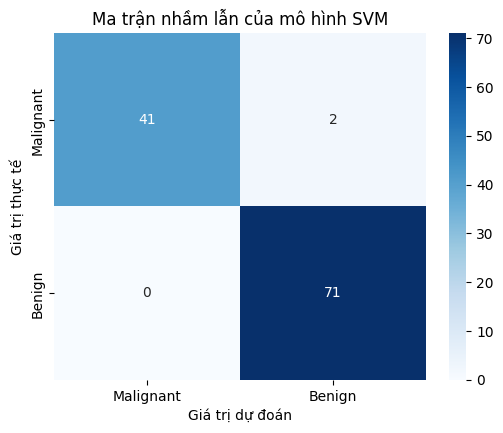

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tải bộ dữ liệu Breast Cancer
cancer = datasets.load_breast_cancer()
X = cancer.data
y = cancer.target

# 2. Chia train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Xây dựng và huấn luyện mô hình SVM với kernel RBF
svm_model = SVC(kernel='rbf', C=1, gamma='scale')
svm_model.fit(X_train, y_train)

# 5. Dự đoán và đánh giá
y_pred = svm_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Độ chính xác của mô hình SVM: {accuracy:.4f}")
print("Ma trận nhầm lẫn:\n", conf_matrix)
print("\nBáo cáo phân loại:\n", classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))

# 6. Trực quan hóa ma trận nhầm lẫn
plt.figure(figsize=(6, 4.5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.xlabel("Giá trị dự đoán")
plt.ylabel("Giá trị thực tế")
plt.title("Ma trận nhầm lẫn của mô hình SVM")
plt.show()

## 2.3. Bài tập tại lớp 1: Thực nghiệm khảo sát các tham số của KNN

**Điểm cốt lõi:**
- Khảo sát ảnh hưởng của việc tăng số lượng láng giềng $K$ từ 1 đến 15 lên độ chính xác dự đoán.
- Đánh giá vai trò quyết định của bước chuẩn hóa dữ liệu qua biểu đồ so sánh trực quan.
- Thử nghiệm các phương pháp tính toán khoảng cách không gian khác nhau (Euclidean, Manhattan, Minkowski) để tìm cấu hình tối ưu nhất cho tập dữ liệu.

K tối ưu (sau chuẩn hóa, Euclidean): K = 1 | Accuracy = 0.9667


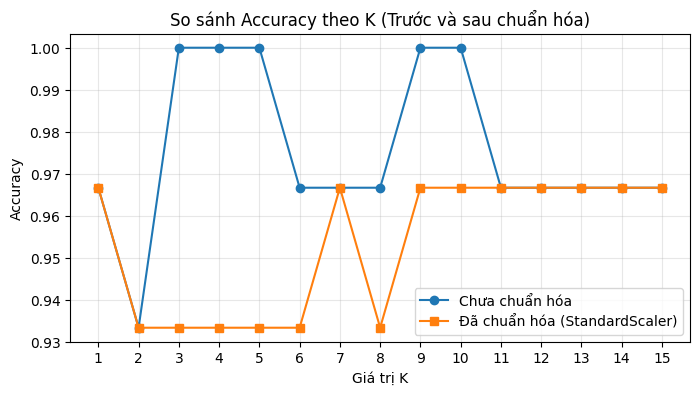


--- So sánh các độ đo khoảng cách (dữ liệu đã chuẩn hóa) ---

Độ đo: Euclidean | Accuracy: 0.9667
Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]

Độ đo: Manhattan | Accuracy: 0.9667
Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]

Độ đo: Minkowski (p=3) | Accuracy: 0.9667
Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Thực nghiệm K từ 1 đến 15
k_values = range(1, 16)
acc_raw, acc_scaled = [], []

for k in k_values:
    m_raw = KNeighborsClassifier(n_neighbors=k, metric="euclidean").fit(X_train, y_train)
    acc_raw.append(accuracy_score(y_test, m_raw.predict(X_test)))

    m_sc = KNeighborsClassifier(n_neighbors=k, metric="euclidean").fit(X_train_sc, y_train)
    acc_scaled.append(accuracy_score(y_test, m_sc.predict(X_test_sc)))

best_k = list(k_values)[int(np.argmax(acc_scaled))]
print(f"K tối ưu (sau chuẩn hóa, Euclidean): K = {best_k} | Accuracy = {max(acc_scaled):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), acc_raw, marker="o", label="Chưa chuẩn hóa")
plt.plot(list(k_values), acc_scaled, marker="s", label="Đã chuẩn hóa (StandardScaler)")
plt.xlabel("Giá trị K")
plt.ylabel("Accuracy")
plt.title("So sánh Accuracy theo K (Trước và sau chuẩn hóa)")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Thực nghiệm các độ đo khoảng cách khác nhau
metrics_config = [
    ("Euclidean", {"metric": "euclidean"}),
    ("Manhattan", {"metric": "manhattan"}),
    ("Minkowski (p=3)", {"metric": "minkowski", "p": 3}),
]

print("\n--- So sánh các độ đo khoảng cách (dữ liệu đã chuẩn hóa) ---")
for name, params in metrics_config:
    clf = KNeighborsClassifier(n_neighbors=best_k, **params).fit(X_train_sc, y_train)
    y_pred = clf.predict(X_test_sc)
    print(f"\nĐộ đo: {name} | Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

## 2.4. Bài tập tại lớp 2: Ước lượng giá trị liên tục bằng KNN Regressor

**Điểm cốt lõi:**
- Ứng dụng KNN vào bài toán hồi quy (dự đoán một số thực liên tục thay vì phân loại nhóm) bằng cách lấy giá trị trung bình từ các láng giềng gần nhất.
- Đánh giá hiệu suất của mô hình khi thay đổi số lượng láng giềng $K$ để tìm ra điểm cân bằng tốt nhất.

In [29]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải dữ liệu Boston Housing
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(url).dropna().select_dtypes(include=[np.number])

X = df.drop(columns=["medv"])
y = df["medv"]

# 2. Chia train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa đặc trưng đầu vào
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# 4 & 5. Thử nghiệm KNN Regressor với k = 3, 5, 7, 9
results = []
for k in [3, 5, 7, 9]:
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_train_sc, y_train)
    y_pred = knn_reg.predict(X_test_sc)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append({"k": k, "MSE": round(mse, 4), "R2_score": round(r2, 4)})
    print(f"k = {k} -> MSE: {mse:.4f} | R^2 score: {r2:.4f}")

print("\nBảng tổng hợp KNN Regressor:")
print(pd.DataFrame(results))

k = 3 -> MSE: 19.4043 | R^2 score: 0.7354
k = 5 -> MSE: 20.6055 | R^2 score: 0.7190
k = 7 -> MSE: 23.4155 | R^2 score: 0.6807
k = 9 -> MSE: 24.0094 | R^2 score: 0.6726

Bảng tổng hợp KNN Regressor:
   k      MSE  R2_score
0  3  19.4043    0.7354
1  5  20.6055    0.7190
2  7  23.4155    0.6807
3  9  24.0094    0.6726


## 2.5. Bài tập tại lớp 3: Đánh giá độ ổn định của mô hình SVM qua các tỷ lệ chia dữ liệu

**Điểm cốt lõi:**
- Khảo sát độ nhạy của thuật toán SVM khi thay đổi tỷ lệ phân chia tập Train/Test (80/20, 70/30, 60/40) và xáo trộn dữ liệu bằng các mã ngẫu nhiên (seed) khác nhau.
- Kết quả thực nghiệm giúp đánh giá độ bền bỉ và khả năng tổng quát hóa của mô hình khi đối mặt với sự thay đổi của dữ liệu đầu vào.

In [30]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X, y = iris.data, iris.target

splits = [
    ("Chia 80/20 (seed=42)", 0.2, 42),
    ("Chia 70/30 (seed=42)", 0.3, 42),
    ("Chia 60/40 (seed=42)", 0.4, 42),
    ("Chia 80/20 (seed=100)", 0.2, 100),
]

summary = []
for label, test_sz, seed in splits:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_sz, random_state=seed, stratify=y
    )

    sc = StandardScaler()
    X_tr_sc = sc.fit_transform(X_tr)
    X_te_sc = sc.transform(X_te)

    svm_clf = SVC(kernel="rbf", C=1.0, gamma="scale").fit(X_tr_sc, y_tr)
    y_pred = svm_clf.predict(X_te_sc)

    acc = accuracy_score(y_te, y_pred)
    summary.append({"Cach_chia": label, "So_mau_test": len(y_te), "Accuracy": round(acc, 4)})

    print("=" * 55)
    print(f"{label} | Số mẫu test: {len(y_te)} | Accuracy: {acc:.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_te, y_pred))

print("\n--- Bảng so sánh các cách chia dữ liệu ---")
print(pd.DataFrame(summary))

Chia 80/20 (seed=42) | Số mẫu test: 30 | Accuracy: 0.9667
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
Chia 70/30 (seed=42) | Số mẫu test: 45 | Accuracy: 0.9333
Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]
Chia 60/40 (seed=42) | Số mẫu test: 60 | Accuracy: 0.9500
Confusion Matrix:
 [[20  0  0]
 [ 0 19  1]
 [ 0  2 18]]
Chia 80/20 (seed=100) | Số mẫu test: 30 | Accuracy: 0.9000
Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  3  7]]

--- Bảng so sánh các cách chia dữ liệu ---
               Cach_chia  So_mau_test  Accuracy
0   Chia 80/20 (seed=42)           30    0.9667
1   Chia 70/30 (seed=42)           45    0.9333
2   Chia 60/40 (seed=42)           60    0.9500
3  Chia 80/20 (seed=100)           30    0.9000


## 2.6. Bài tập tại lớp 4: Dự báo giá nhà sử dụng thuật toán hồi quy SVM (SVR)

**Điểm cốt lõi:**
- Chuyển đổi thuật toán SVM từ phân loại sang hồi quy (SVR).
- So sánh trực tiếp hiệu quả giữa đường ranh giới tuyến tính (`linear`) và đường ranh giới cong phi tuyến (`rbf`) để thấy rõ khả năng xử lý các quy luật biến động phức tạp của dữ liệu thực tế.

In [31]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải dữ liệu Boston Housing
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(url).dropna().select_dtypes(include=[np.number])

X = df.drop(columns=["medv"])
y = df["medv"]

# 2. Chia train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa đặc trưng đầu vào
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# 4. Huấn luyện và đánh giá SVR với kernel 'linear' và 'rbf'
svr_results = []
for ker in ["linear", "rbf"]:
    svr_model = SVR(kernel=ker, C=1.0)
    svr_model.fit(X_train_sc, y_train)
    y_pred = svr_model.predict(X_test_sc)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    svr_results.append({"kernel": ker, "MSE": round(mse, 4), "R2_score": round(r2, 4)})
    print(f"SVR (kernel='{ker}') -> MSE: {mse:.4f} | R^2 score: {r2:.4f}")

print("\nBảng so sánh SVR:")
print(pd.DataFrame(svr_results))

SVR (kernel='linear') -> MSE: 28.9185 | R^2 score: 0.6057
SVR (kernel='rbf') -> MSE: 25.6685 | R^2 score: 0.6500

Bảng so sánh SVR:
   kernel      MSE  R2_score
0  linear  28.9185    0.6057
1     rbf  25.6685    0.6500


## 2.7. Bài tập về nhà 1: Khảo sát sức mạnh của các hàm nhân (Kernel) trong SVM

**Điểm cốt lõi:**
- Thực nghiệm đo lường hiệu năng của 4 loại hàm nhân phổ biến trong SVM (`linear`, `rbf`, `poly`, `sigmoid`) trên cùng một tập dữ liệu chuẩn hóa.
- Bảng kết quả cuối cùng xếp hạng độ chính xác giúp đưa ra lựa chọn kỹ thuật tối ưu nhất cho cấu trúc dữ liệu đang xử lý.

In [32]:
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

cancer = datasets.load_breast_cancer()
X, y = cancer.data, cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

results = []
for ker in ["linear", "rbf", "poly", "sigmoid"]:
    model = SVC(kernel=ker, C=1.0, gamma="scale", random_state=42)
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_test_sc)

    acc = accuracy_score(y_test, y_pred)
    results.append({"kernel": ker, "Accuracy": round(acc, 4)})

    print("=" * 55)
    print(f"Kernel = '{ker}' | Accuracy = {acc:.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\n--- Bảng tổng hợp hiệu suất theo kernel ---")
print(pd.DataFrame(results).sort_values(by="Accuracy", ascending=False))

Kernel = 'linear' | Accuracy = 0.9737
Confusion Matrix:
 [[41  1]
 [ 2 70]]
Kernel = 'rbf' | Accuracy = 0.9825
Confusion Matrix:
 [[41  1]
 [ 1 71]]
Kernel = 'poly' | Accuracy = 0.9123
Confusion Matrix:
 [[32 10]
 [ 0 72]]
Kernel = 'sigmoid' | Accuracy = 0.9298
Confusion Matrix:
 [[39  3]
 [ 5 67]]

--- Bảng tổng hợp hiệu suất theo kernel ---
    kernel  Accuracy
1      rbf    0.9825
0   linear    0.9737
3  sigmoid    0.9298
2     poly    0.9123


## 2.8. Bài tập về nhà 2: Tự động hóa quá trình tìm tham số tối ưu bằng GridSearchCV

**Điểm cốt lõi:**
- Thay vì thử sai thủ công, công cụ `GridSearchCV` sẽ tự động quét qua toàn bộ các tổ hợp thiết lập (giá trị $C$, các loại Kernel, hệ số Gamma) kết hợp kiểm định chéo để tìm ra cấu hình đạt độ chính xác cao nhất.
- Đánh giá độc lập mô hình tối ưu tìm được trên tập kiểm tra để đảm bảo kết quả trung thực.

In [33]:
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

cancer = datasets.load_breast_cancer()
X, y = cancer.data, cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Khai báo lưới siêu tham số
param_grid = {
    "kernel": ["linear", "rbf", "poly"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.01, 0.001],
}

grid_search = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)
grid_search.fit(X_train_sc, y_train)

print("Bộ siêu tham số tối ưu:", grid_search.best_params_)
print(f"Accuracy trung bình tốt nhất trên CV (train): {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test_sc)
print(f"Accuracy trên tập kiểm tra (test): {accuracy_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix trên tập test:\n", confusion_matrix(y_test, y_pred))

cv_df = pd.DataFrame(grid_search.cv_results_)[
    ["params", "mean_test_score", "rank_test_score"]
].sort_values(by="rank_test_score")
print("\nTop 5 cấu hình tốt nhất:")
print(cv_df.head(5).to_string(index=False))

Bộ siêu tham số tối ưu: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Accuracy trung bình tốt nhất trên CV (train): 0.9802
Accuracy trên tập kiểm tra (test): 0.9825

Confusion Matrix trên tập test:
 [[41  1]
 [ 1 71]]

Top 5 cấu hình tốt nhất:
                                          params  mean_test_score  rank_test_score
{'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}          0.98022                1
 {'C': 0.1, 'gamma': 'auto', 'kernel': 'linear'}          0.98022                1
   {'C': 0.1, 'gamma': 0.01, 'kernel': 'linear'}          0.98022                1
  {'C': 0.1, 'gamma': 0.001, 'kernel': 'linear'}          0.98022                1
       {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}          0.98022                1


## 2.9. Bài tập về nhà 3: Nhận diện chữ số viết tay (Tập dữ liệu Digits)

**Điểm cốt lõi:**
- Thử thách các thuật toán phân loại trên tập dữ liệu ảnh số viết tay độ phân giải thấp (mỗi ảnh là một lưới pixel 8x8, tương đương 64 biến đầu vào).
- Huấn luyện song song thuật toán KNN và thuật toán SVM với các hàm nhân khác nhau, sau đó đặt ma trận nhầm lẫn của từng mô hình cạnh nhau để so sánh trực quan khả năng nhận diện các chữ số từ 0 đến 9.

Kích thước dữ liệu Digits: (1797, 64) | Các lớp: [0 1 2 3 4 5 6 7 8 9]
Mô hình: KNN (K=5) | Accuracy: 0.9639
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9231    1.0000    0.9600        36
           2     0.9459    1.0000    0.9722        35
           3     1.0000    0.9730    0.9863        37
           4     0.9714    0.9444    0.9577        36
           5     0.9730    0.9730    0.9730        37
           6     0.9730    1.0000    0.9863        36
           7     0.9211    0.9722    0.9459        36
           8     0.9688    0.8857    0.9254        35
           9     0.9697    0.8889    0.9275        36

    accuracy                         0.9639       360
   macro avg     0.9646    0.9637    0.9634       360
weighted avg     0.9648    0.9639    0.9636       360

Mô hình: SVM (kernel='poly') | Accuracy: 0.9722
              precision    recall  f1-score   support

           0     1.0000    0.

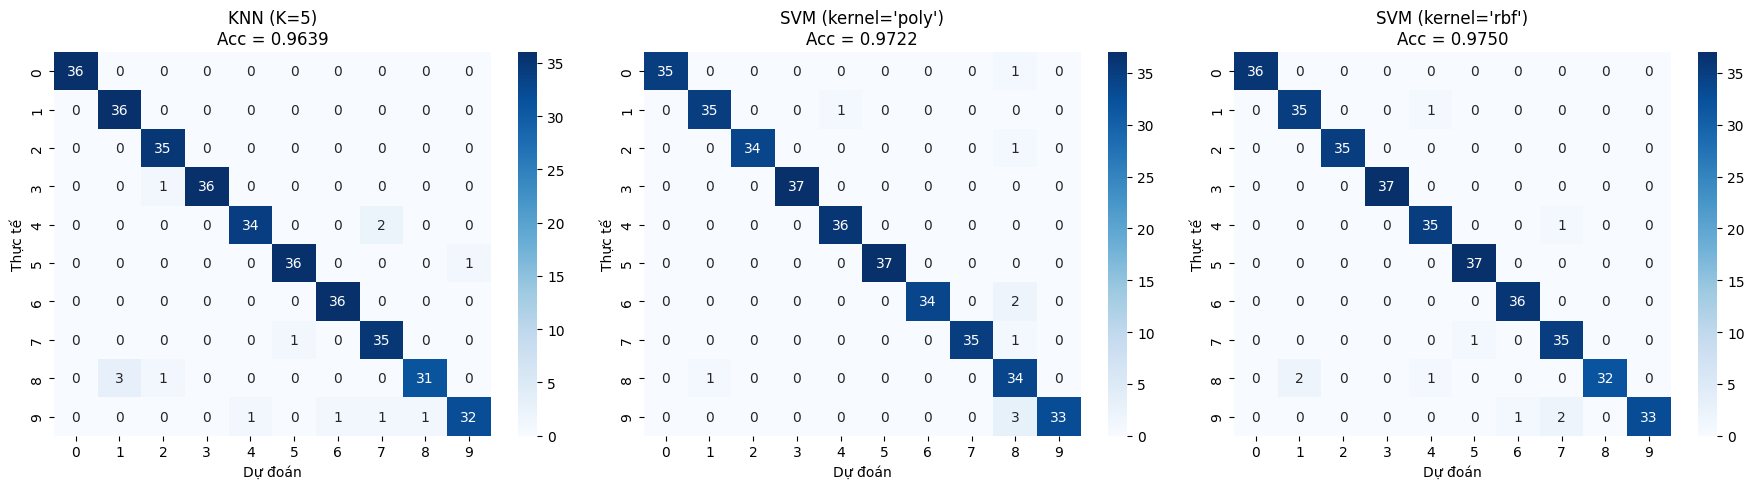

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tải tập dữ liệu Digits
digits = load_digits()
X, y = digits.data, digits.target
print(f"Kích thước dữ liệu Digits: {X.shape} | Các lớp: {digits.target_names}")

# 2. Chia train/test và chuẩn hóa dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# 3. Huấn luyện lần lượt KNN, SVM (poly) và SVM (rbf)
models = {
    "KNN (K=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (kernel='poly')": SVC(kernel="poly", C=1.0, gamma="scale", random_state=42),
    "SVM (kernel='rbf')": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42),
}

conf_matrices = {}
scores = {}

for name, model in models.items():
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_test_sc)

    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    scores[name] = acc
    conf_matrices[name] = cm

    print("=" * 55)
    print(f"Mô hình: {name} | Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, digits=4))

# 4. So sánh độ chính xác và vẽ 3 ma trận nhầm lẫn
print("\n--- Bảng so sánh độ chính xác ---")
for name, acc in sorted(scores.items(), key=lambda x: x[1], reverse=True):
    print(f"- {name}: {acc:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=digits.target_names,
        yticklabels=digits.target_names,
        ax=ax,
    )
    ax.set_title(f"{name}\nAcc = {scores[name]:.4f}")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")

plt.tight_layout()
plt.show()